In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import pairwise_distances

In [4]:
df = pd.read_csv(
    'input_data.txt',
    sep=';',
    skiprows=1,
    names=['start_date_time', 'RCORR_E'],
    parse_dates=['start_date_time']
)

print(df.head())

      start_date_time  RCORR_E
0 2026-02-01 00:00:00  185.200
1 2026-02-01 00:01:00  185.067
2 2026-02-01 00:02:00  187.333
3 2026-02-01 00:03:00  186.800
4 2026-02-01 00:04:00  189.733


In [5]:
full_range = pd.date_range(
    start=df['start_date_time'].min(),
    end=df['start_date_time'].max(),
    freq='1min'
)

existing = set(df['start_date_time'])

missing_minutes = [t for t in full_range if t not in existing]

if missing_minutes:
    df_missing = pd.DataFrame({
        'start_date_time': missing_minutes,
        'RCORR_E': np.nan
    })
    df = pd.concat([df, df_missing], ignore_index=True)
    df = df.sort_values('start_date_time').reset_index(drop=True)

In [6]:
df_sigma = df.copy()

missing_mask = df_sigma['RCORR_E'].isna()

valid_data = df_sigma.loc[~missing_mask, 'RCORR_E']
mean_val = valid_data.mean()
std_val = valid_data.std()

outlier_mask = (df_sigma['RCORR_E'] < mean_val - 3 * std_val) | \
               (df_sigma['RCORR_E'] > mean_val + 3 * std_val)
outlier_mask = outlier_mask & (~missing_mask)

clean_data_sigma = df_sigma.loc[~missing_mask & ~outlier_mask, 'RCORR_E']
median_sigma = clean_data_sigma.median()

df_sigma.loc[missing_mask | outlier_mask, 'RCORR_E'] = median_sigma

In [7]:
with open('clear_data.txt', 'w') as f:
    f.write('start_date_time RCORR_E\n')

df_sigma.to_csv(
    'clear_data.txt',
    sep=';',
    index=False,
    header=False,
    mode='a',
    date_format='%Y-%m-%d %H:%M:%S',
    float_format='%.3f'
)

In [10]:
df = pd.read_csv(
    'clear_data.txt',
    sep=';',
    skiprows=1,
    names=['start_date_time', 'RCORR_E'],
    parse_dates=['start_date_time']
)

series = df['RCORR_E'].values
print(df.head())

      start_date_time  RCORR_E
0 2026-02-01 00:00:00  185.200
1 2026-02-01 00:01:00  185.067
2 2026-02-01 00:02:00  187.333
3 2026-02-01 00:03:00  186.800
4 2026-02-01 00:04:00  189.733


In [11]:
m = 180
k = 3

if len(series) <= m:
    raise ValueError(f"Длина ряда ({len(series)}) должна быть больше m ({m}).")

history_vectors = []
targets = []

for i in range(len(series) - m):
    history_vectors.append(series[i : i + m])
    targets.append(series[i + m])

history_vectors = np.array(history_vectors)
targets = np.array(targets)
test_vector = series[-m:].reshape(1, -1)

print(f"\nСформировано векторов-историй: {len(history_vectors)}")



Сформировано векторов-историй: 19980


In [12]:
metrics = ['euclidean', 'manhattan', 'chebyshev']
neighbors_dict = {}

print("\n--- Поиск ближайших соседей ---")
for metric in metrics:
    distances = pairwise_distances(test_vector, history_vectors, metric=metric).flatten()

    nearest_indices = np.argsort(distances)[:k]

    neighbors_dict[metric] = {
        'indices': nearest_indices,
        'distances': distances[nearest_indices]
    }

    print(f"\nМетрика: {metric}")
    print(f"  Индексы соседей: {nearest_indices}")
    print(f"  Расстояния: {distances[nearest_indices]}")


--- Поиск ближайших соседей ---

Метрика: euclidean
  Индексы соседей: [19162 15140 19180]
  Расстояния: [40.19539862 41.5334343  42.05367395]

Метрика: manhattan
  Индексы соседей: [19162 15140 17605]
  Расстояния: [435.34  438.127 442.396]

Метрика: chebyshev
  Индексы соседей: [16631 19162 15963]
  Расстояния: [7.466 7.6   7.6  ]


In [13]:
predictions = {}

print("\n--- Прогнозирование ---")
for metric in metrics:
    neighbor_indices = neighbors_dict[metric]['indices']
    neighbor_targets = targets[neighbor_indices]

    # Прогноз как простое среднее следующих значений
    prediction = np.mean(neighbor_targets)
    predictions[metric] = prediction

    print(f"Метрика: {metric}")
    print(f"  Значения следующих точек у соседей: {neighbor_targets}")
    print(f"  Прогноз (среднее): {prediction:.4f}")

ensemble_prediction = np.mean(list(predictions.values()))
print(f"\nАнсамблевый прогноз (среднее по 3 метрикам): {ensemble_prediction:.4f}")



--- Прогнозирование ---
Метрика: euclidean
  Значения следующих точек у соседей: [195.733 195.2   195.333]
  Прогноз (среднее): 195.4220
Метрика: manhattan
  Значения следующих точек у соседей: [195.733 195.2   196.533]
  Прогноз (среднее): 195.8220
Метрика: chebyshev
  Значения следующих точек у соседей: [191.6   195.733 196.   ]
  Прогноз (среднее): 194.4443

Ансамблевый прогноз (среднее по 3 метрикам): 195.2294


Сохранен график: plots/neighbors_euclidean.png


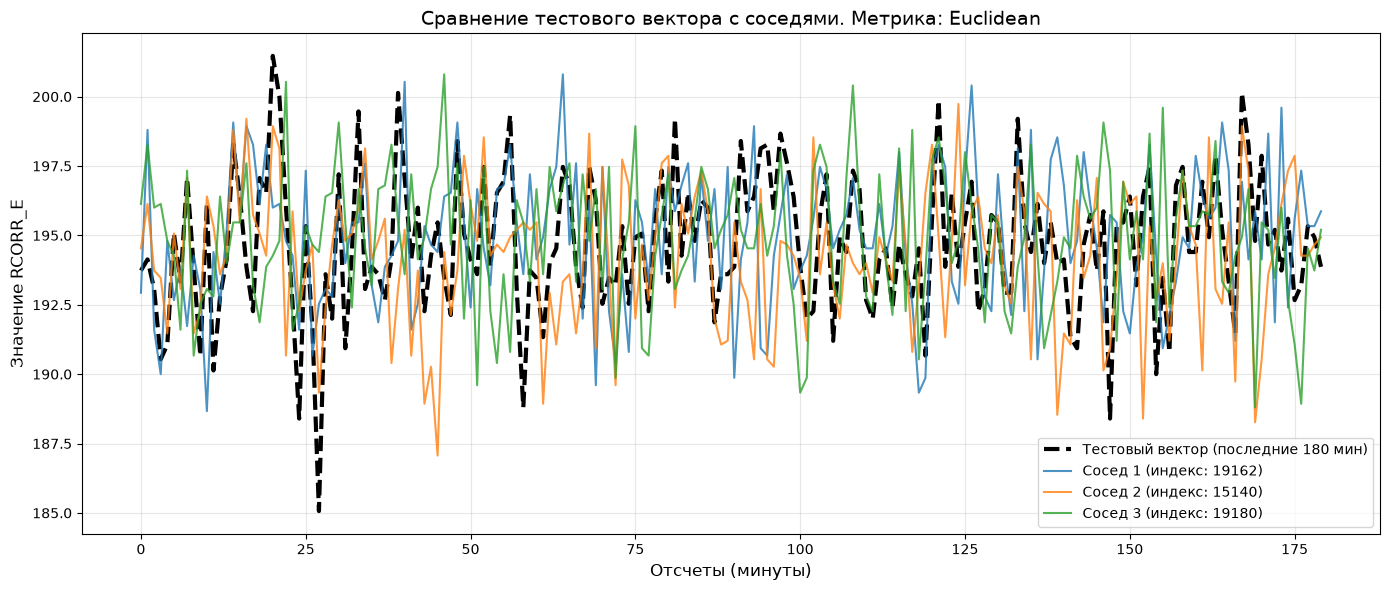

Сохранен график: plots/neighbors_manhattan.png


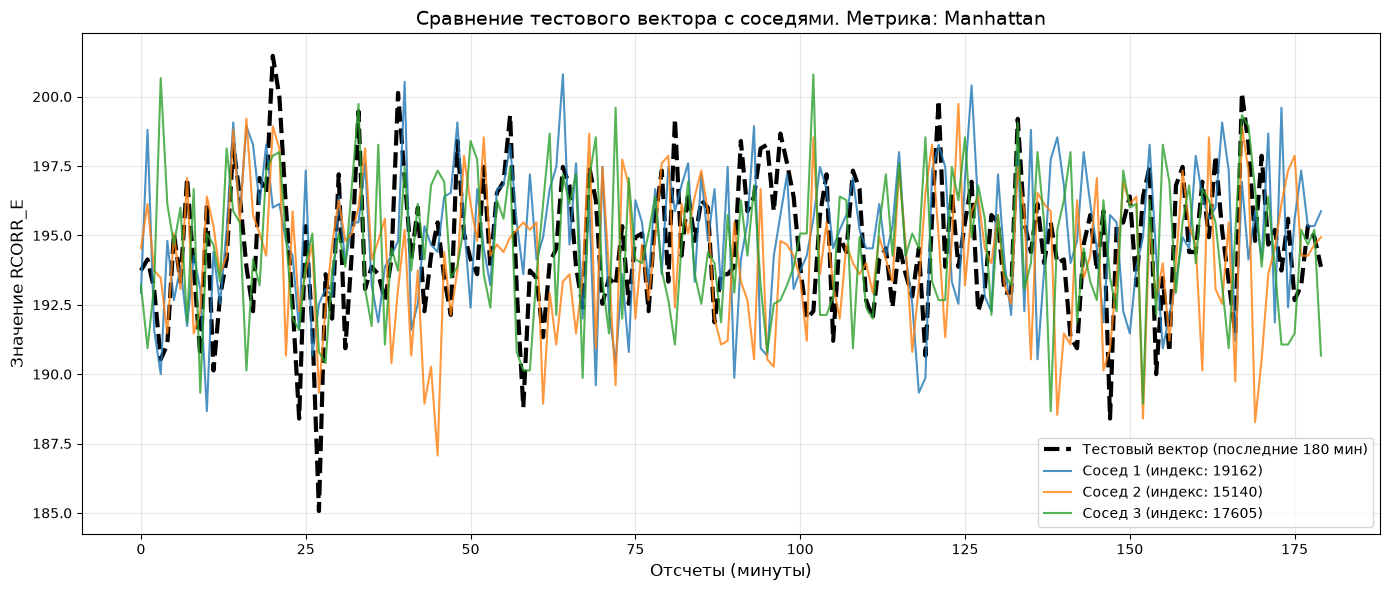

Сохранен график: plots/neighbors_chebyshev.png


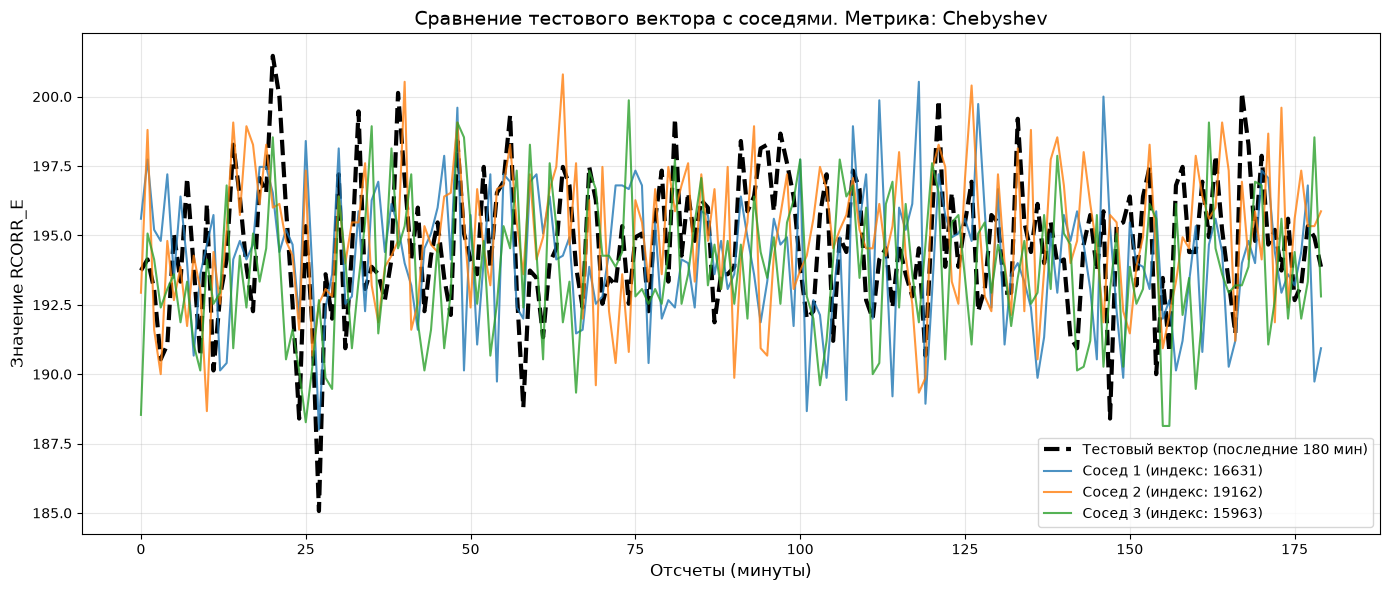

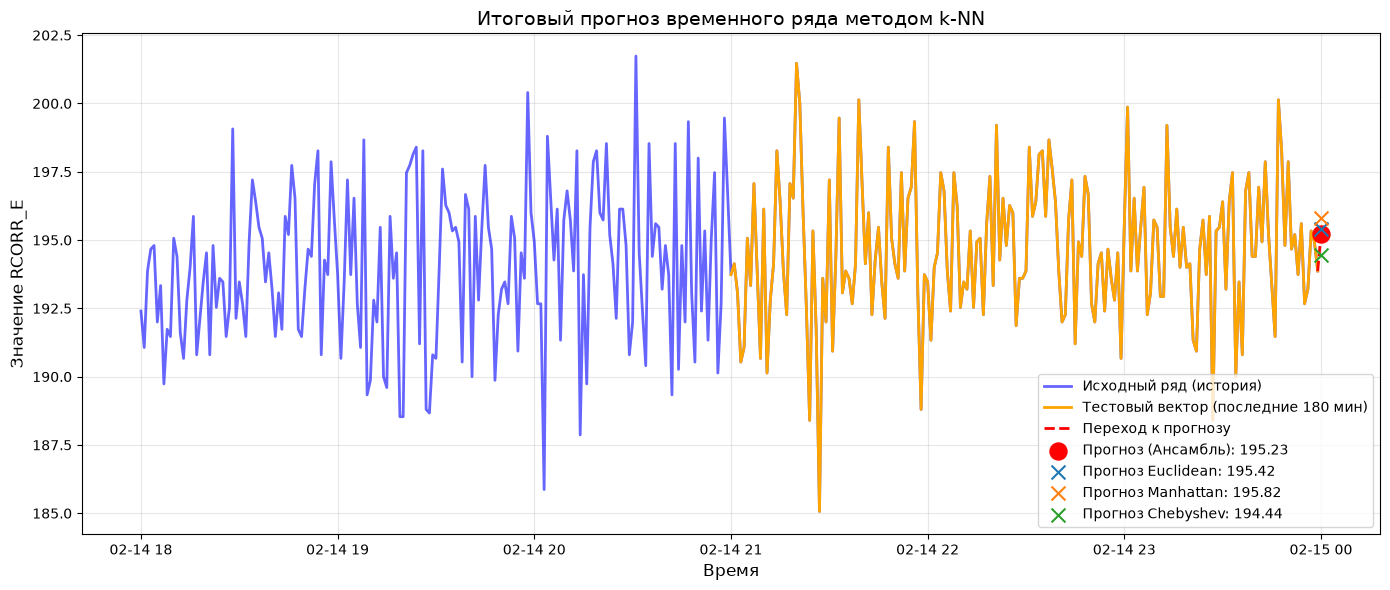

In [16]:
import os

output_dir = 'plots'
os.makedirs(output_dir, exist_ok=True)

for metric in metrics:
    plt.figure(figsize=(14, 6))

    plt.plot(test_vector.flatten(), label='Тестовый вектор (последние 180 мин)',
             color='black', linewidth=3, linestyle='--')

    indices = neighbors_dict[metric]['indices']

    for j, idx in enumerate(indices):
        plt.plot(history_vectors[idx], label=f'Сосед {j+1} (индекс: {idx})',
                 alpha=0.8, linewidth=1.5)

    plt.title(f'Сравнение тестового вектора с соседями. Метрика: {metric.capitalize()}', fontsize=14)
    plt.xlabel('Отсчеты (минуты)', fontsize=12)
    plt.ylabel('Значение RCORR_E', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = os.path.join(output_dir, f'neighbors_{metric}.png')
    plt.savefig(filename, dpi=300)
    print(f"Сохранен график: {filename}")
    plt.show()
    plt.close()

plt.figure(figsize=(14, 6))

plot_window = m * 2
if len(df) < plot_window:
    plot_window = len(df)

historical_data = df.iloc[-plot_window:]
plt.plot(historical_data['start_date_time'], historical_data['RCORR_E'],
         label='Исходный ряд (история)', color='blue', alpha=0.6, linewidth=2)

test_data = df.iloc[-m:]
plt.plot(test_data['start_date_time'], test_data['RCORR_E'],
         label='Тестовый вектор (последние 180 мин)', color='orange', linewidth=2)

last_time = df['start_date_time'].iloc[-1]
next_time = last_time + pd.Timedelta(minutes=1) # Следующая минута
last_value = df['RCORR_E'].iloc[-1]

plt.plot([last_time, next_time],
         [last_value, ensemble_prediction],
         color='red', linestyle='--', linewidth=2, label='Переход к прогнозу')

plt.scatter([next_time], [ensemble_prediction], color='red', s=150, zorder=5,
            label=f'Прогноз (Ансамбль): {ensemble_prediction:.2f}')

for metric, pred in predictions.items():
    plt.scatter([next_time], [pred], marker='x', s=100, zorder=6,
                label=f'Прогноз {metric.capitalize()}: {pred:.2f}')

plt.title('Итоговый прогноз временного ряда методом k-NN', fontsize=14)
plt.xlabel('Время', fontsize=12)
plt.ylabel('Значение RCORR_E', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()

filename = os.path.join(output_dir, 'final_forecast.png')
plt.savefig(filename, dpi=300)
plt.show()
plt.close()